# Lei de Zipf nos municípios do Ceará (versão 5)

Esta é a quinta versão da análise, que acompanha o artigo curto (`artigo/artigo_v5.typ`, 3 páginas). Ela segue a sequência de Newman (2005): **medir** (distribuição cumulativa), **estimar** (máxima verossimilhança com $x_{\min}$), **testar** (aderência e comparação com a log-normal) e **interpretar** (variação do maior valor e mecanismo de crescimento proporcional).

As seções 1 a 14 são as mesmas da versão 4 (Ceará e comparação com os nove estados do Nordeste). São novas:

- a seção 15, que compara a lei de potência com a distribuição log-normal pelo teste da razão de verossimilhança de Clauset, Shalizi e Newman (2009) e testa a aderência da log-normal por bootstrap;
- a seção 16, que gera a figura do artigo v5.

O notebook da versão 4 não foi alterado. As saídas desta versão vão para `notebook_output/v5/`.

## 1. Preparação do ambiente

Na raiz do projeto, instale as dependências com o [uv](https://docs.astral.sh/uv/):

```bash
uv sync
```

Depois, escolha o kernel `.venv` no VS Code (ou rode `uv run jupyter lab`) e execute as células em ordem com **Shift + Enter**. Para executar tudo pelo terminal:

```bash
uv run --with nbconvert --with nbclient jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=1200 Lei_de_Zipf_Ceara_v5.ipynb
```

## 2. Importações e pastas

Os arquivos baixados serão guardados em `data` e as saídas desta versão em `notebook_output/v5`.

In [1]:
import gzip
import json
import math
from pathlib import Path
from urllib.request import urlopen

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from scipy import optimize, special, stats

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUTPUT = ROOT / 'notebook_output' / 'v5'
DATA.mkdir(exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)

print('Pasta atual:', ROOT)
print('Python e bibliotecas carregados com sucesso.')

Pasta atual: /home/davvi/Programing/Unifor/ciencia_cidades
Python e bibliotecas carregados com sucesso.


## 3. Coleta dos dados oficiais do IBGE

A primeira URL consulta a tabela SIDRA 4709, variável 93, referente à população residente no Censo 2022. `N6[N3[23]]` significa municípios pertencentes ao Ceará, cujo código é 23. A segunda URL baixa a malha municipal em GeoJSON.

In [2]:
POP_URL = (
    'https://servicodados.ibge.gov.br/api/v3/agregados/4709/periodos/2022/'
    'variaveis/93?localidades=N6[N3[23]]'
)
MAP_URL = (
    'https://servicodados.ibge.gov.br/api/v3/malhas/estados/23?'
    'formato=application/vnd.geo+json&qualidade=minima&intrarregiao=municipio'
)

population_path = DATA / 'ibge_populacao_ceara_2022.json'
map_path = DATA / 'ibge_malha_municipal_ceara.geojson'

def descompactar_se_gzip(conteudo):
    # A API do IBGE pode devolver o corpo compactado em gzip (bytes iniciais 1f 8b).
    # O urlopen não descompacta sozinho, então fazemos isso aqui.
    return gzip.decompress(conteudo) if conteudo[:2] == b'\x1f\x8b' else conteudo

def baixar_se_necessario(url, destino):
    if destino.exists():
        conteudo = destino.read_bytes()
        if conteudo[:2] == b'\x1f\x8b':
            # Arquivo salvo por uma versão anterior do notebook, ainda compactado.
            destino.write_bytes(descompactar_se_gzip(conteudo))
            print(f'Arquivo já existente (descompactado): {destino.name}')
        else:
            print(f'Arquivo já existente: {destino.name}')
        return
    print(f'Baixando {destino.name}...')
    with urlopen(url, timeout=90) as resposta:
        destino.write_bytes(descompactar_se_gzip(resposta.read()))
    print('Download concluído.')

baixar_se_necessario(POP_URL, population_path)
baixar_se_necessario(MAP_URL, map_path)

Arquivo já existente: ibge_populacao_ceara_2022.json
Arquivo já existente: ibge_malha_municipal_ceara.geojson


## 4. Tratamento, ranking e logaritmos

As cidades são ordenadas da maior para a menor população. Em seguida, calculamos $x=\log_{10}(rank)$ e $y=\log_{10}(população)$.

In [3]:
raw = json.loads(population_path.read_text(encoding='utf-8'))
series = raw[0]['resultados'][0]['series']

rows = []
for item in series:
    localidade = item['localidade']
    rows.append({
        'codigo_ibge': localidade['id'],
        'municipio': localidade['nome'].removesuffix(' - CE'),
        'populacao': int(item['serie']['2022']),
    })

df = pd.DataFrame(rows).sort_values('populacao', ascending=False).reset_index(drop=True)
df['rank'] = np.arange(1, len(df) + 1)
df['log10_rank'] = np.log10(df['rank'])
df['log10_populacao'] = np.log10(df['populacao'])

print('Número de municípios:', len(df))
display(df.head(10))

Número de municípios: 184


,codigo_ibge,municipio,populacao,rank,log10_rank,log10_populacao
0,2304400,Fortaleza,2428708,1,0.000000,6.385375
1,2303709,Caucaia,355679,2,0.301030,5.551058
2,2307304,Juazeiro do Norte,286120,3,0.477121,5.456548
3,2307650,Maracanaú,234509,4,0.602060,5.370160
4,2312908,Sobral,203023,5,0.698970,5.307545
5,2306405,Itapipoca,131123,6,0.778151,5.117679
6,2304202,Crato,131050,7,0.845098,5.117437
7,2307700,Maranguape,105093,8,0.903090,5.021574
8,2305506,Iguatu,98064,9,0.954243,4.991510
9,2311306,Quixadá,84168,10,1.000000,4.925147


## 5. Cálculo manual da regressão, de $q$ e de $R^2$

A inclinação é calculada por $\hat{\beta}=S_{xy}/S_{xx}$. Como o modelo é $y=\alpha-qx$, temos $q=-\hat{\beta}$. O coeficiente de determinação é $R^2=1-SSE/SST$. A função também calcula o intervalo de confiança e testa se a inclinação é igual a -1.

In [4]:
def ajustar_rank_size(amostra):
    x = amostra['log10_rank'].to_numpy()
    y = amostra['log10_populacao'].to_numpy()

    x_media = x.mean()
    y_media = y.mean()
    sxx = np.sum((x - x_media) ** 2)
    sxy = np.sum((x - x_media) * (y - y_media))
    beta = sxy / sxx
    intercepto = y_media - beta * x_media
    q = -beta

    y_estimado = intercepto + beta * x
    sse = np.sum((y - y_estimado) ** 2)
    sst = np.sum((y - y_media) ** 2)
    r2 = 1 - sse / sst

    n = len(amostra)
    graus_liberdade = n - 2
    erro_padrao_beta = np.sqrt((sse / graus_liberdade) / sxx)
    t_critico = stats.t.ppf(0.975, graus_liberdade)
    ic_inferior = beta - t_critico * erro_padrao_beta
    ic_superior = beta + t_critico * erro_padrao_beta
    t_zipf = (beta - (-1)) / erro_padrao_beta
    p_zipf = 2 * stats.t.sf(abs(t_zipf), graus_liberdade)

    return {
        'n': n, 'media_x': x_media, 'media_y': y_media,
        'Sxx': sxx, 'Sxy': sxy, 'intercepto': intercepto,
        'beta': beta, 'q': q, 'SSE': sse, 'SST': sst, 'R2': r2,
        'erro_padrao_beta': erro_padrao_beta,
        'IC95_inferior': ic_inferior, 'IC95_superior': ic_superior,
        't_teste_beta_menos_1': t_zipf, 'p_teste_beta_menos_1': p_zipf,
    }

resultado_184 = ajustar_rank_size(df)
resultado_top20 = ajustar_rank_size(df.head(20))

## 6. Resultados das duas amostras

O primeiro modelo usa todos os 184 municípios. O segundo usa somente os 20 maiores.

In [5]:
comparacao = pd.DataFrame([
    {'amostra': '184 municípios', **resultado_184},
    {'amostra': '20 maiores', **resultado_top20},
])[['amostra', 'n', 'Sxx', 'Sxy', 'beta', 'q', 'SSE', 'SST', 'R2',
    'IC95_inferior', 'IC95_superior', 'p_teste_beta_menos_1']]

display(comparacao.round(6))
print(f"184 municípios: q = {resultado_184['q']:.4f} e R² = {resultado_184['R2']:.4f}")
print(f"20 maiores:     q = {resultado_top20['q']:.4f} e R² = {resultado_top20['R2']:.4f}")

,amostra,n,Sxx,Sxy,beta,q,SSE,SST,R2,IC95_inferior,IC95_superior,p_teste_beta_menos_1
0,184 municípios,184,31.271361,-28.191121,-0.901500,0.901500,1.613769,27.028054,0.940293,-0.934724,-0.868275,0.000000
1,20 maiores,20,2.366990,-2.339318,-0.988309,0.988309,0.282747,2.594717,0.891030,-1.159458,-0.817160,0.887483


184 municípios: q = 0.9015 e R² = 0.9403
20 maiores:     q = 0.9883 e R² = 0.8910


## 7. Conferência numérica do cálculo principal

Esta célula mostra explicitamente as substituições usadas no artigo. Pequenas diferenças na última casa decimal podem ocorrer apenas por arredondamento de exibição.

In [6]:
r = resultado_184
print(f"β = Sxy / Sxx = {r['Sxy']:.4f} / {r['Sxx']:.4f} = {r['beta']:.4f}")
print(f"q = -β = {r['q']:.4f}")
print(f"R² = 1 - SSE/SST = 1 - {r['SSE']:.4f}/{r['SST']:.4f} = {r['R2']:.4f}")

β = Sxy / Sxx = -28.1911 / 31.2714 = -0.9015
q = -β = 0.9015
R² = 1 - SSE/SST = 1 - 1.6138/27.0281 = 0.9403


## 8. Estatísticas auxiliares

Calculamos a participação de Fortaleza, a razão Fortaleza/Caucaia e o Gini da população municipal.

In [7]:
def gini(valores):
    valores = np.sort(np.asarray(valores, dtype=float))
    n = valores.size
    return (2 * np.sum(np.arange(1, n + 1) * valores) / (n * valores.sum())) - (n + 1) / n

pop_total = int(df['populacao'].sum())
fortaleza = df.iloc[0]
caucaia = df.iloc[1]
participacao = 100 * fortaleza['populacao'] / pop_total
razao = fortaleza['populacao'] / caucaia['populacao']
gini_pop = gini(df['populacao'])

print(f'População somada dos municípios: {pop_total:,}'.replace(',', '.'))
print(f'Participação de Fortaleza: {participacao:.2f}%')
print(f'Razão Fortaleza/Caucaia: {razao:.2f}')
print(f'Gini das populações municipais: {gini_pop:.4f}')

População somada dos municípios: 8.794.957
Participação de Fortaleza: 27.61%
Razão Fortaleza/Caucaia: 6.83
Gini das populações municipais: 0.6172


## 9. Mapa e gráfico da Lei de Zipf

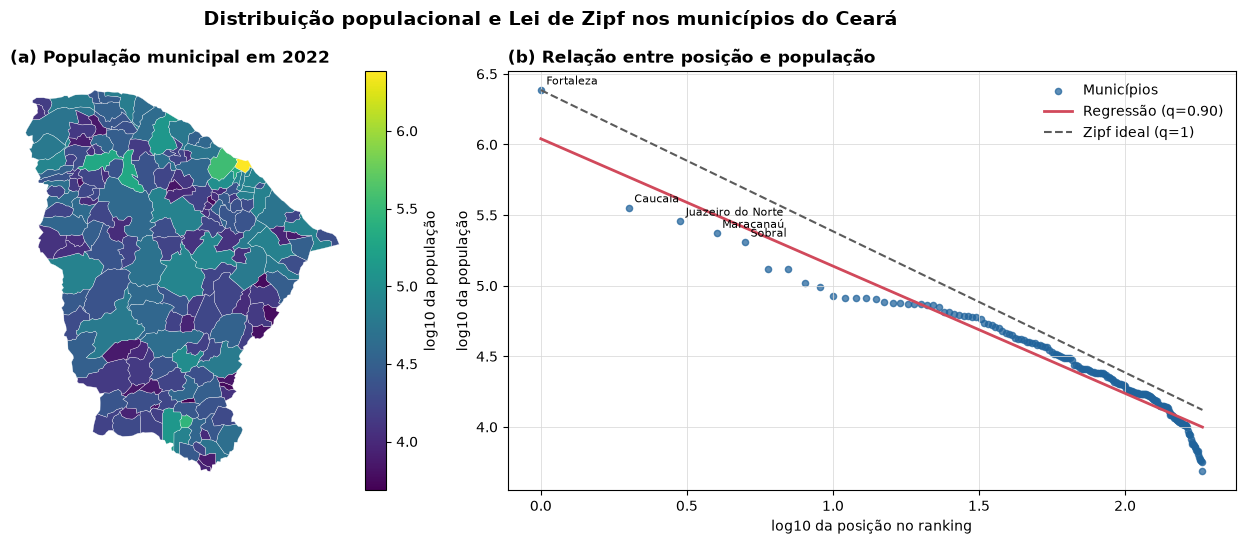

In [8]:
def geometria_para_poligonos(geometria):
    patches = []
    if geometria['type'] == 'Polygon':
        poligonos = [geometria['coordinates']]
    elif geometria['type'] == 'MultiPolygon':
        poligonos = geometria['coordinates']
    else:
        return patches
    for poligono in poligonos:
        if poligono and len(poligono[0]) >= 3:
            patches.append(MplPolygon(np.asarray(poligono[0]), closed=True))
    return patches

geo = json.loads(map_path.read_text(encoding='utf-8'))
pop_por_codigo = df.set_index('codigo_ibge')['populacao'].to_dict()
fig, (ax_mapa, ax_zipf) = plt.subplots(1, 2, figsize=(14, 5.5),
    gridspec_kw={'width_ratios': [0.9, 1.25]})

patches, valores = [], []
for feature in geo['features']:
    codigo = feature['properties']['codarea']
    populacao = pop_por_codigo.get(codigo)
    if populacao is None:
        continue
    partes = geometria_para_poligonos(feature['geometry'])
    patches.extend(partes)
    valores.extend([math.log10(populacao)] * len(partes))

colecao = PatchCollection(patches, cmap='viridis', edgecolor='white', linewidth=0.22)
colecao.set_array(np.asarray(valores))
ax_mapa.add_collection(colecao)
ax_mapa.autoscale_view()
ax_mapa.set_aspect('equal')
ax_mapa.axis('off')
ax_mapa.set_title('(a) População municipal em 2022', loc='left', fontweight='bold')
fig.colorbar(colecao, ax=ax_mapa, fraction=0.046, pad=0.02, label='log10 da população')

x = df['log10_rank'].to_numpy()
y = df['log10_populacao'].to_numpy()
x_linha = np.linspace(0, x.max(), 200)
ajustada = resultado_184['intercepto'] + resultado_184['beta'] * x_linha
zipf_ideal = y[0] - x_linha
ax_zipf.scatter(x, y, s=20, alpha=0.72, color='#20639B', label='Municípios')
ax_zipf.plot(x_linha, ajustada, color='#D1495B', linewidth=2,
    label=f"Regressão (q={resultado_184['q']:.2f})")
ax_zipf.plot(x_linha, zipf_ideal, '--', color='#5B5B5B', label='Zipf ideal (q=1)')
for _, linha in df.head(5).iterrows():
    ax_zipf.annotate(linha['municipio'], (linha['log10_rank'], linha['log10_populacao']),
                     xytext=(4, 4), textcoords='offset points', fontsize=8)
ax_zipf.set_title('(b) Relação entre posição e população', loc='left', fontweight='bold')
ax_zipf.set_xlabel('log10 da posição no ranking')
ax_zipf.set_ylabel('log10 da população')
ax_zipf.grid(True, color='#D9D9D9', linewidth=0.55)
ax_zipf.legend(frameon=False)
fig.suptitle('Distribuição populacional e Lei de Zipf nos municípios do Ceará',
             fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'figura_zipf_ceara.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Exportação dos resultados

In [9]:
df.to_csv(OUTPUT / 'municipios_ceara_populacao_2022.csv', index=False, encoding='utf-8-sig')
comparacao.to_csv(OUTPUT / 'resultados_regressao.csv', index=False, encoding='utf-8-sig')

resumo = {
    'fonte': 'IBGE, Censo Demográfico 2022, SIDRA, tabela 4709, variável 93',
    'numero_municipios': len(df),
    'populacao_total': pop_total,
    'participacao_fortaleza_percentual': participacao,
    'razao_fortaleza_caucaia': razao,
    'gini': gini_pop,
    'regressao_184': resultado_184,
    'regressao_20_maiores': resultado_top20,
}
(OUTPUT / 'resultados_resumo.json').write_text(
    json.dumps(resumo, ensure_ascii=False, indent=2), encoding='utf-8')

print('Arquivos salvos em:', OUTPUT.resolve())

Arquivos salvos em: /home/davvi/Programing/Unifor/ciencia_cidades/notebook_output/v5


## 11. Valores esperados para validar a reprodução

Se tudo foi executado corretamente, os resultados devem ser aproximadamente:

| Resultado | Valor esperado |
|---|---:|
| Número de municípios | 184 |
| $q$ para os 184 municípios | 0,9015 |
| $R^2$ para os 184 municípios | 0,9403 |
| $q$ para os 20 maiores | 0,9883 |
| $R^2$ para os 20 maiores | 0,8910 |
| Participação de Fortaleza | 27,61% |
| Razão Fortaleza/Caucaia | 6,83 |
| Gini municipal | 0,6172 |

Para recomeçar do zero, apague as pastas `data` e `notebook_output` e execute novamente todas as células.

## 12. Comparação com os estados do Nordeste

Para saber se o padrão cearense é particular, o mesmo estudo é repetido para os nove estados do Nordeste. Comparar o Ceará com os vizinhos tem duas vantagens sobre a comparação da versão 3: os estados têm história de povoamento, clima e economia mais parecidos, e o conjunto não é escolhido a dedo, porque é a região inteira.

A fonte é a mesma (Censo 2022, SIDRA 4709, variável 93) e o método também: ranking, regressão de $\log_{10}(população)$ sobre $\log_{10}(posição)$ para todos os municípios e para os 20 maiores, participação da maior cidade, razão entre a primeira e a segunda e Gini. Os estados estão em ordem geográfica, de oeste para leste e de norte para sul; o Ceará entra na tabela para facilitar a comparação, e seus valores são os mesmos das seções anteriores.

In [10]:
ESTADOS = {
    'MA': {'codigo': 21, 'nome': 'Maranhão', 'arquivo': 'maranhao'},
    'PI': {'codigo': 22, 'nome': 'Piauí', 'arquivo': 'piaui'},
    'CE': {'codigo': 23, 'nome': 'Ceará', 'arquivo': 'ceara'},
    'RN': {'codigo': 24, 'nome': 'Rio Grande do Norte', 'arquivo': 'rio_grande_do_norte'},
    'PB': {'codigo': 25, 'nome': 'Paraíba', 'arquivo': 'paraiba'},
    'PE': {'codigo': 26, 'nome': 'Pernambuco', 'arquivo': 'pernambuco'},
    'AL': {'codigo': 27, 'nome': 'Alagoas', 'arquivo': 'alagoas'},
    'SE': {'codigo': 28, 'nome': 'Sergipe', 'arquivo': 'sergipe'},
    'BA': {'codigo': 29, 'nome': 'Bahia', 'arquivo': 'bahia'},
}
def carregar_estado(sigla):
    info = ESTADOS[sigla]
    pop_path = DATA / f"ibge_populacao_{info['arquivo']}_2022.json"
    malha_path = DATA / f"ibge_malha_municipal_{info['arquivo']}.geojson"
    baixar_se_necessario(
        'https://servicodados.ibge.gov.br/api/v3/agregados/4709/periodos/2022/'
        f"variaveis/93?localidades=N6[N3[{info['codigo']}]]", pop_path)
    baixar_se_necessario(
        f"https://servicodados.ibge.gov.br/api/v3/malhas/estados/{info['codigo']}?"
        'formato=application/vnd.geo+json&qualidade=minima&intrarregiao=municipio', malha_path)

    series = json.loads(pop_path.read_text(encoding='utf-8'))[0]['resultados'][0]['series']
    tabela = pd.DataFrame([{
        'codigo_ibge': item['localidade']['id'],
        'municipio': item['localidade']['nome'].removesuffix(f' - {sigla}'),
        'populacao': int(item['serie']['2022']),
    } for item in series])
    tabela = tabela.sort_values('populacao', ascending=False).reset_index(drop=True)
    tabela['rank'] = np.arange(1, len(tabela) + 1)
    tabela['log10_rank'] = np.log10(tabela['rank'])
    tabela['log10_populacao'] = np.log10(tabela['populacao'])
    malha = json.loads(malha_path.read_text(encoding='utf-8'))
    return tabela, malha

estados = {sigla: carregar_estado(sigla) for sigla in ESTADOS}
for sigla, (tabela, _) in estados.items():
    print(f"{ESTADOS[sigla]['nome']}: {len(tabela)} municípios")

# Contorno dos estados do Nordeste (região 2 do IBGE), usado só no mapa.
malha_uf_path = DATA / 'ibge_malha_nordeste_uf.geojson'
baixar_se_necessario(
    'https://servicodados.ibge.gov.br/api/v3/malhas/regioes/2?'
    'formato=application/vnd.geo+json&qualidade=minima&intrarregiao=UF', malha_uf_path)
malha_uf = json.loads(malha_uf_path.read_text(encoding='utf-8'))

Arquivo já existente: ibge_populacao_maranhao_2022.json
Arquivo já existente: ibge_malha_municipal_maranhao.geojson
Arquivo já existente: ibge_populacao_piaui_2022.json
Arquivo já existente: ibge_malha_municipal_piaui.geojson
Arquivo já existente: ibge_populacao_ceara_2022.json
Arquivo já existente: ibge_malha_municipal_ceara.geojson
Arquivo já existente: ibge_populacao_rio_grande_do_norte_2022.json
Arquivo já existente: ibge_malha_municipal_rio_grande_do_norte.geojson
Arquivo já existente: ibge_populacao_paraiba_2022.json
Arquivo já existente: ibge_malha_municipal_paraiba.geojson
Arquivo já existente: ibge_populacao_pernambuco_2022.json
Arquivo já existente: ibge_malha_municipal_pernambuco.geojson
Arquivo já existente: ibge_populacao_alagoas_2022.json
Arquivo já existente: ibge_malha_municipal_alagoas.geojson
Arquivo já existente: ibge_populacao_sergipe_2022.json
Arquivo já existente: ibge_malha_municipal_sergipe.geojson
Arquivo já existente: ibge_populacao_bahia_2022.json
Arquivo já 

In [11]:
linhas_regressao, linhas_concentracao = [], []
resultados_estados = {}

for sigla, (tabela, _) in estados.items():
    todos = ajustar_rank_size(tabela)
    maiores = ajustar_rank_size(tabela.head(20))
    resultados_estados[sigla] = {'todos': todos, '20 maiores': maiores}
    for amostra, r in [('todos', todos), ('20 maiores', maiores)]:
        linhas_regressao.append({'UF': sigla, 'amostra': amostra, **r})

    pop = tabela['populacao']
    linhas_concentracao.append({
        'UF': sigla,
        'municipios': len(tabela),
        'populacao_total': int(pop.sum()),
        'maior_municipio': tabela.loc[0, 'municipio'],
        'populacao_maior': int(pop.iloc[0]),
        'segundo_municipio': tabela.loc[1, 'municipio'],
        'participacao_maior_percentual': 100 * pop.iloc[0] / pop.sum(),
        'razao_primeiro_segundo': pop.iloc[0] / pop.iloc[1],
        'gini': gini(pop),
        # População que a reta ajustada a todos os municípios prevê para a 1ª posição.
        'maior_prevista_pela_reta': 10 ** todos['intercepto'],
    })

concentracao_estados = pd.DataFrame(linhas_concentracao)
regressao_estados = pd.DataFrame(linhas_regressao)[[
    'UF', 'amostra', 'n', 'beta', 'q', 'R2', 'IC95_inferior', 'IC95_superior',
    'p_teste_beta_menos_1']]

display(concentracao_estados.round(4))
display(regressao_estados.round(4))

,UF,municipios,populacao_total,maior_municipio,populacao_maior,segundo_municipio,participacao_maior_percentual,razao_primeiro_segundo,gini,maior_prevista_pela_reta
0,MA,217,6776699,São Luís,1037775,Imperatriz,15.3139,3.7998,0.5473,7.657371e+05
1,PI,224,3271199,Teresina,866300,Parnaíba,26.4826,5.3423,0.6220,3.431830e+05
2,CE,184,8794957,Fortaleza,2428708,Caucaia,27.6148,6.8284,0.6172,1.098117e+06
3,RN,167,3302729,Natal,751300,Mossoró,22.7479,2.8396,0.6697,5.934700e+05
4,PB,223,3974687,João Pessoa,833932,Campina Grande,20.9811,1.9885,0.6477,5.843813e+05
5,PE,185,9058931,Recife,1488920,Jaboatão dos Guararapes,16.4359,2.3119,0.6222,1.495241e+06
6,AL,102,3127683,Maceió,957916,Arapiraca,30.6270,4.0815,0.6105,4.603910e+05
7,SE,75,2210004,Aracaju,602757,Nossa Senhora do Socorro,27.2740,3.1340,0.6355,5.569950e+05
8,BA,417,14141626,Salvador,2417678,Feira de Santana,17.0962,3.9231,0.5836,1.234294e+06


,UF,amostra,n,beta,q,R2,IC95_inferior,IC95_superior,p_teste_beta_menos_1
0,MA,todos,217,-0.8455,0.8455,0.9502,-0.8715,-0.8194,0.0000
1,MA,20 maiores,20,-0.8407,0.8407,0.9572,-0.9288,-0.7527,0.0013
2,PI,todos,224,-0.8678,0.8678,0.9747,-0.8862,-0.8493,0.0000
3,PI,20 maiores,20,-0.9061,0.9061,0.8642,-1.0840,-0.7283,0.2821
4,CE,todos,184,-0.9015,0.9015,0.9403,-0.9347,-0.8683,0.0000
5,CE,20 maiores,20,-0.9883,0.9883,0.8910,-1.1595,-0.8172,0.8875
6,RN,todos,167,-1.0194,1.0194,0.9701,-1.0469,-0.9919,0.1654
7,RN,20 maiores,20,-1.0757,1.0757,0.9732,-1.1640,-0.9874,0.0886
8,PB,todos,223,-0.9605,0.9605,0.9557,-0.9880,-0.9331,0.0050
9,PB,20 maiores,20,-1.1024,1.1024,0.9626,-1.2100,-0.9949,0.0607


### Teste $q = 1$ com o erro padrão de Gabaix e Ibragimov

O erro padrão da seção 5 supõe resíduos independentes, mas no gráfico rank-size os pontos vizinhos são correlacionados, porque cada posição depende de todas as cidades maiores. Por isso, o intervalo de confiança da regressão fica estreito demais. Gabaix e Ibragimov (2011) mostram que o erro padrão assintótico de $q$ é $q\sqrt{2/n}$. A célula abaixo refaz o teste $q = 1$ com esse erro; os dois intervalos aparecem no painel (c) da figura seguinte.

In [12]:
linhas_gi = []
for sigla in ESTADOS:
    for amostra, r in resultados_estados[sigla].items():
        erro_gi = r['q'] * np.sqrt(2 / r['n'])
        linhas_gi.append({
            'UF': sigla, 'amostra': amostra, 'n': r['n'], 'q': r['q'],
            'erro_padrao_regressao': r['erro_padrao_beta'],
            'erro_padrao_gabaix_ibragimov': erro_gi,
            'q_IC95_inferior_GI': r['q'] - 1.96 * erro_gi,
            'q_IC95_superior_GI': r['q'] + 1.96 * erro_gi,
            'p_q_igual_1_GI': 2 * stats.norm.sf(abs(r['q'] - 1) / erro_gi),
        })
gabaix_ibragimov = pd.DataFrame(linhas_gi)
gabaix_ibragimov.to_csv(OUTPUT / 'erro_padrao_gabaix_ibragimov.csv', index=False, encoding='utf-8-sig')
display(gabaix_ibragimov.round(4))

,UF,amostra,n,q,erro_padrao_regressao,erro_padrao_gabaix_ibragimov,q_IC95_inferior_GI,q_IC95_superior_GI,p_q_igual_1_GI
0,MA,todos,217,0.8455,0.0132,0.0812,0.6864,1.0045,0.0569
1,MA,20 maiores,20,0.8407,0.0419,0.2659,0.3196,1.3618,0.5491
2,PI,todos,224,0.8678,0.0094,0.0820,0.7070,1.0285,0.1068
3,PI,20 maiores,20,0.9061,0.0847,0.2865,0.3445,1.4678,0.7432
4,CE,todos,184,0.9015,0.0168,0.0940,0.7173,1.0857,0.2946
5,CE,20 maiores,20,0.9883,0.0815,0.3125,0.3757,1.6009,0.9702
6,RN,todos,167,1.0194,0.0139,0.1116,0.8008,1.2381,0.8619
7,RN,20 maiores,20,1.0757,0.0421,0.3402,0.4090,1.7424,0.8239
8,PB,todos,223,0.9605,0.0139,0.0910,0.7822,1.1388,0.6644
9,PB,20 maiores,20,1.1024,0.0512,0.3486,0.4191,1.7858,0.7689


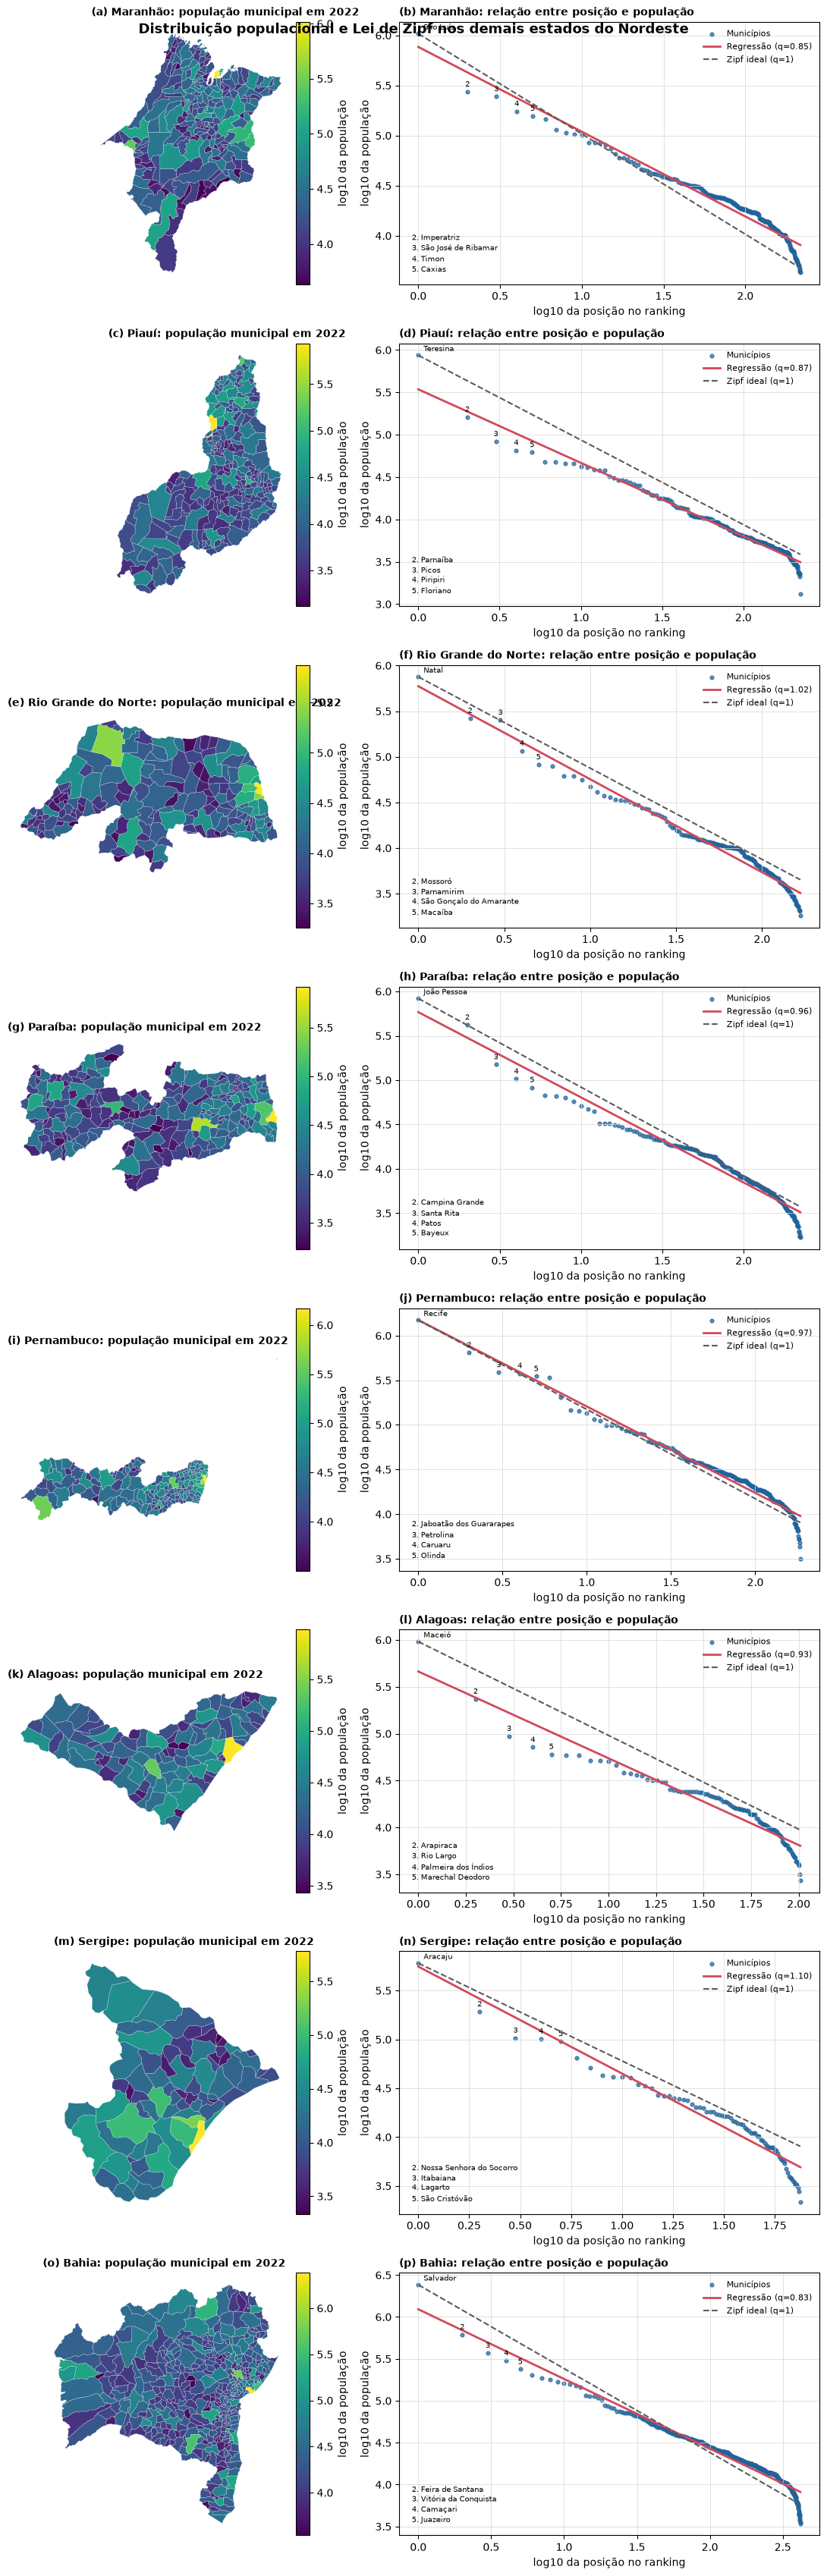

In [13]:
def desenhar_estado(ax_mapa, ax_zipf, tabela, malha, resultado, nome, letras):
    pop_por_codigo = tabela.set_index('codigo_ibge')['populacao'].to_dict()
    patches, valores = [], []
    for feature in malha['features']:
        populacao = pop_por_codigo.get(feature['properties']['codarea'])
        if populacao is None:
            continue
        partes = geometria_para_poligonos(feature['geometry'])
        patches.extend(partes)
        valores.extend([math.log10(populacao)] * len(partes))

    colecao = PatchCollection(patches, cmap='viridis', edgecolor='white', linewidth=0.15)
    colecao.set_array(np.asarray(valores))
    ax_mapa.add_collection(colecao)
    ax_mapa.autoscale_view()
    ax_mapa.set_aspect('equal')
    ax_mapa.axis('off')
    ax_mapa.set_title(f'({letras[0]}) {nome}: população municipal em 2022', loc='left',
                      fontweight='bold', fontsize=10)
    plt.colorbar(colecao, ax=ax_mapa, fraction=0.046, pad=0.02, label='log10 da população')

    x = tabela['log10_rank'].to_numpy()
    y = tabela['log10_populacao'].to_numpy()
    x_linha = np.linspace(0, x.max(), 200)
    ax_zipf.scatter(x, y, s=12, alpha=0.72, color='#20639B', label='Municípios')
    ax_zipf.plot(x_linha, resultado['intercepto'] + resultado['beta'] * x_linha, color='#D1495B',
                 linewidth=2, label=f"Regressão (q={resultado['q']:.2f})")
    ax_zipf.plot(x_linha, y[0] - x_linha, '--', color='#5B5B5B', label='Zipf ideal (q=1)')
    # A maior cidade é rotulada ao lado do ponto. Da 2ª à 5ª os pontos ficam muito próximos,
    # então cada um recebe só o número da posição, e os nomes vão para uma lista no canto.
    primeira = tabela.iloc[0]
    ax_zipf.annotate(primeira['municipio'], (primeira['log10_rank'], primeira['log10_populacao']),
                     xytext=(5, 4), textcoords='offset points', fontsize=7)
    for _, linha in tabela.iloc[1:5].iterrows():
        ax_zipf.annotate(str(linha['rank']), (linha['log10_rank'], linha['log10_populacao']),
                         xytext=(0, 5), textcoords='offset points', fontsize=7, ha='center')
    lista = '\n'.join(f"{linha['rank']}. {linha['municipio']}" for _, linha in tabela.iloc[1:5].iterrows())
    ax_zipf.text(0.03, 0.04, lista, transform=ax_zipf.transAxes, fontsize=7, va='bottom',
                 linespacing=1.4)
    ax_zipf.set_title(f'({letras[1]}) {nome}: relação entre posição e população', loc='left',
                      fontweight='bold', fontsize=10)
    ax_zipf.set_xlabel('log10 da posição no ranking')
    ax_zipf.set_ylabel('log10 da população')
    ax_zipf.grid(True, color='#D9D9D9', linewidth=0.55)
    ax_zipf.legend(frameon=False, fontsize=8)

outros = [sigla for sigla in ESTADOS if sigla != 'CE']
letras = 'abcdefghijklmnopqrstuvwxyz'
fig, eixos = plt.subplots(len(outros), 2, figsize=(11, 4.3 * len(outros)),
                          gridspec_kw={'width_ratios': [0.9, 1.25]})
for i, ((ax_mapa, ax_zipf), sigla) in enumerate(zip(eixos, outros)):
    tabela, malha = estados[sigla]
    desenhar_estado(ax_mapa, ax_zipf, tabela, malha, resultados_estados[sigla]['todos'],
                    ESTADOS[sigla]['nome'], letras[2 * i:2 * i + 2])
fig.suptitle('Distribuição populacional e Lei de Zipf nos demais estados do Nordeste',
             fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'figura_zipf_outros_estados.png', dpi=300, bbox_inches='tight')
plt.show()

A figura abaixo resume a comparação. Em (a), o mapa mostra a população de todos os municípios da região na mesma escala de cores. Em (b), a população de cada município é dividida pela do maior município do seu estado, de modo que todas as curvas começam no zero; o Ceará aparece em destaque, os demais em cinza, e a linha tracejada é a Lei de Zipf estrita. Em (c), aparece o expoente $q$ dos 20 maiores municípios com os dois intervalos de 95%: o do erro usual da regressão e o do erro de Gabaix e Ibragimov.

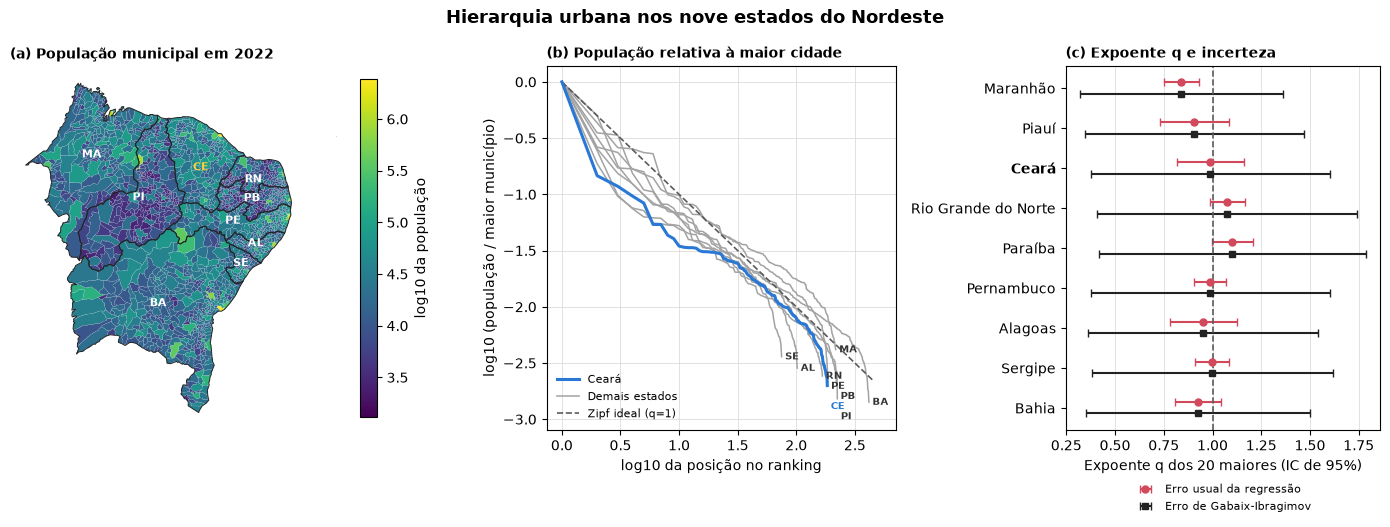

In [14]:
# Com nove estados, cores diferentes não se distinguem numa mesma área de gráfico.
# O Ceará fica em destaque e os demais em cinza, identificados pela sigla.
COR_CEARA, COR_OUTROS = '#2a78d6', '#A3A3A3'
SIGLA_POR_CODIGO = {str(info['codigo']): sigla for sigla, info in ESTADOS.items()}

fig = plt.figure(figsize=(14, 5.4))
grade = fig.add_gridspec(1, 3, width_ratios=[1.05, 1, 0.9])
ax_mapa, ax_curvas, ax_q = (fig.add_subplot(grade[0, i]) for i in range(3))

patches, valores = [], []
for sigla, (tabela, malha) in estados.items():
    pop_por_codigo = tabela.set_index('codigo_ibge')['populacao'].to_dict()
    for feature in malha['features']:
        populacao = pop_por_codigo.get(feature['properties']['codarea'])
        if populacao is None:
            continue
        partes = geometria_para_poligonos(feature['geometry'])
        patches.extend(partes)
        valores.extend([math.log10(populacao)] * len(partes))
colecao = PatchCollection(patches, cmap='viridis', edgecolor='white', linewidth=0.05)
colecao.set_array(np.asarray(valores))
ax_mapa.add_collection(colecao)
for feature in malha_uf['features']:
    partes = geometria_para_poligonos(feature['geometry'])
    ax_mapa.add_collection(PatchCollection(partes, facecolor='none', edgecolor='#222222', linewidth=0.7))
    # A sigla vai no centro do maior polígono do estado.
    maior_parte = max(partes, key=lambda p: len(p.get_xy()))
    cx, cy = maior_parte.get_xy().mean(axis=0)
    sigla = SIGLA_POR_CODIGO[feature['properties']['codarea']]
    ax_mapa.text(cx, cy, sigla, ha='center', va='center', fontsize=8, fontweight='bold',
                 color='white' if sigla != 'CE' else '#FFD23F')
ax_mapa.autoscale_view()
ax_mapa.set_aspect('equal')
ax_mapa.axis('off')
ax_mapa.set_title('(a) População municipal em 2022', loc='left', fontweight='bold', fontsize=10)
fig.colorbar(colecao, ax=ax_mapa, fraction=0.046, pad=0.02, label='log10 da população')

fins = []
for sigla, (tabela, _) in estados.items():
    x = tabela['log10_rank'].to_numpy()
    y = tabela['log10_populacao'].to_numpy() - tabela['log10_populacao'].iloc[0]
    destaque = sigla == 'CE'
    ax_curvas.plot(x, y, color=COR_CEARA if destaque else COR_OUTROS, linewidth=2.2 if destaque else 1.1,
                   zorder=3 if destaque else 2, label='Ceará' if destaque else None)
    fins.append([x[-1], y[-1], sigla])
# Várias curvas terminam no mesmo ponto; os rótulos próximos são afastados na vertical.
fins.sort(key=lambda f: -f[1])
for anterior, atual in zip(fins, fins[1:]):
    if abs(atual[0] - anterior[0]) < 0.2 and anterior[1] - atual[1] < 0.09:
        atual[1] = anterior[1] - 0.09
for x_fim, y_rotulo, sigla in fins:
    ax_curvas.text(x_fim + 0.03, y_rotulo, sigla, va='center', fontsize=7.5, fontweight='bold',
                   color=COR_CEARA if sigla == 'CE' else '#333333')
ax_curvas.set_xlim(right=2.85)
ax_curvas.set_ylim(bottom=min(f[1] for f in fins) - 0.12)
ax_curvas.plot([], [], color=COR_OUTROS, linewidth=1.1, label='Demais estados')
x_ref = np.linspace(0, 2.65, 50)
ax_curvas.plot(x_ref, -x_ref, '--', color='#5B5B5B', linewidth=1.2, label='Zipf ideal (q=1)')
ax_curvas.set_title('(b) População relativa à maior cidade', loc='left', fontweight='bold', fontsize=10)
ax_curvas.set_xlabel('log10 da posição no ranking')
ax_curvas.set_ylabel('log10 (população / maior município)')
ax_curvas.grid(True, color='#D9D9D9', linewidth=0.55)
ax_curvas.legend(frameon=False, fontsize=8, loc='lower left')

siglas = list(ESTADOS)
posicoes = np.arange(len(siglas))
gi_20 = gabaix_ibragimov[gabaix_ibragimov['amostra'] == '20 maiores'].set_index('UF').loc[siglas]
qs = gi_20['q'].to_numpy()
usual_inf = np.array([-resultados_estados[s]['20 maiores']['IC95_superior'] for s in siglas])
usual_sup = np.array([-resultados_estados[s]['20 maiores']['IC95_inferior'] for s in siglas])
ax_q.errorbar(qs, posicoes - 0.14, xerr=[qs - usual_inf, usual_sup - qs], fmt='o', color='#D1495B',
              elinewidth=1.5, capsize=3, markersize=5, label='Erro usual da regressão')
ax_q.errorbar(qs, posicoes + 0.14,
              xerr=[qs - gi_20['q_IC95_inferior_GI'].to_numpy(), gi_20['q_IC95_superior_GI'].to_numpy() - qs],
              fmt='s', color='#222222', elinewidth=1.5, capsize=3, markersize=5,
              label='Erro de Gabaix-Ibragimov')
ax_q.axvline(1, color='#5B5B5B', linestyle='--', linewidth=1.2)
ax_q.set_yticks(posicoes, [ESTADOS[s]['nome'] for s in siglas])
ax_q.get_yticklabels()[siglas.index('CE')].set_fontweight('bold')
ax_q.invert_yaxis()
ax_q.set_xlabel('Expoente q dos 20 maiores (IC de 95%)')
ax_q.set_title('(c) Expoente q e incerteza', loc='left', fontweight='bold', fontsize=10)
ax_q.grid(True, axis='x', color='#D9D9D9', linewidth=0.55)
ax_q.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncols=1)

fig.suptitle('Hierarquia urbana nos nove estados do Nordeste', fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'figura_comparacao_nordeste.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
concentracao_estados.to_csv(OUTPUT / 'comparacao_estados_concentracao.csv', index=False,
                            encoding='utf-8-sig')
regressao_estados.to_csv(OUTPUT / 'comparacao_estados_regressao.csv', index=False,
                         encoding='utf-8-sig')
for sigla, (tabela, _) in estados.items():
    if sigla != 'CE':
        tabela.to_csv(OUTPUT / f"municipios_{ESTADOS[sigla]['arquivo']}_populacao_2022.csv",
                      index=False, encoding='utf-8-sig')
print('Arquivos da comparação salvos em:', OUTPUT.resolve())

Arquivos da comparação salvos em: /home/davvi/Programing/Unifor/ciencia_cidades/notebook_output/v5


### Valores esperados da comparação

| Resultado | Maranhão | Piauí | Ceará | Rio Grande do Norte | Paraíba | Pernambuco | Alagoas | Sergipe | Bahia |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Municípios | 217 | 224 | 184 | 167 | 223 | 185 | 102 | 75 | 417 |
| Maior município | São Luís | Teresina | Fortaleza | Natal | João Pessoa | Recife | Maceió | Aracaju | Salvador |
| Participação da maior cidade | 15,31% | 26,48% | 27,61% | 22,75% | 20,98% | 16,44% | 30,63% | 27,27% | 17,10% |
| Razão 1ª/2ª | 3,80 | 5,34 | 6,83 | 2,84 | 1,99 | 2,31 | 4,08 | 3,13 | 3,92 |
| Gini municipal | 0,5473 | 0,6220 | 0,6172 | 0,6697 | 0,6477 | 0,6222 | 0,6105 | 0,6355 | 0,5836 |
| $q$ (todos) | 0,8455 | 0,8678 | 0,9015 | 1,0194 | 0,9605 | 0,9685 | 0,9254 | 1,0953 | 0,8315 |
| $R^2$ (todos) | 0,9502 | 0,9747 | 0,9403 | 0,9701 | 0,9557 | 0,9605 | 0,9181 | 0,9391 | 0,9560 |
| $q$ (20 maiores) | 0,8407 | 0,9061 | 0,9883 | 1,0757 | 1,1024 | 0,9886 | 0,9518 | 0,9981 | 0,9267 |
| $R^2$ (20 maiores) | 0,9572 | 0,8642 | 0,8910 | 0,9732 | 0,9626 | 0,9732 | 0,8825 | 0,9699 | 0,9383 |
| $p$ do teste $q = 1$, 20 maiores, erro usual | 0,001 | 0,282 | 0,887 | 0,089 | 0,061 | 0,772 | 0,564 | 0,963 | 0,207 |
| $p$ do teste $q = 1$, todos, erro de Gabaix-Ibragimov | 0,057 | 0,107 | 0,295 | 0,862 | 0,664 | 0,754 | 0,565 | 0,594 | 0,003 |
| $p$ do teste $q = 1$, 20 maiores, erro de Gabaix-Ibragimov | 0,549 | 0,743 | 0,970 | 0,824 | 0,769 | 0,971 | 0,873 | 0,995 | 0,802 |

## 13. Estimação por máxima verossimilhança (Newman, 2005)

Newman (2005) mostra que o gráfico rank-size é a distribuição cumulativa complementar $P(X \ge x)$ desenhada com os eixos trocados (Apêndice A do artigo). Se a densidade segue $p(x) = Cx^{-\alpha}$, a posição $r$ de uma cidade de tamanho $x$ é proporcional a $x^{-(\alpha-1)}$, e portanto $x \propto r^{-1/(\alpha-1)}$. Assim, o expoente de Zipf e o expoente da lei de potência se relacionam por

$$q = \frac{1}{\alpha - 1} \qquad \Longleftrightarrow \qquad \alpha = 1 + \frac{1}{q},$$

e a Lei de Zipf estrita ($q = 1$) corresponde a $\alpha = 2$.

O artigo faz dois alertas sobre o método das seções anteriores:

1. **O ajuste por mínimos quadrados da reta em escala log-log é enviesado** e não deve ser usado como estimativa principal do expoente. O recomendado é o estimador de máxima verossimilhança (Eq. 5 do artigo), $\hat\alpha = 1 + n\left[\sum_{i=1}^{n}\ln(x_i/x_{\min})\right]^{-1}$, com erro padrão $\sigma = (\hat\alpha - 1)/\sqrt{n}$ (Eq. 6).
2. **Poucas distribuições reais seguem a lei de potência em toda a faixa**; ela costuma valer só acima de um valor mínimo $x_{\min}$ (a "cauda"). Usar todos os municípios mistura a cauda com a parte de baixo, que segue outra forma.

Para escolher $x_{\min}$ sem arbitrariedade, usamos o critério de Clauset, Shalizi e Newman (2009): testamos cada população observada como candidata a $x_{\min}$ (exigindo pelo menos 10 municípios na cauda), estimamos $\hat\alpha$ e escolhemos o $x_{\min}$ que minimiza a distância de Kolmogorov-Smirnov $D$ entre a distribuição empírica e a ajustada. A aderência é avaliada por bootstrap paramétrico: geramos 1.000 amostras sintéticas do mesmo tamanho (cauda sorteada da lei de potência ajustada e parte de baixo reamostrada dos dados), repetimos todo o ajuste em cada uma e calculamos a fração $p$ de amostras com $D$ maior ou igual ao observado. Pelo critério dos autores, $p < 0{,}1$ indica que a lei de potência não é um modelo plausível.

Por fim, Newman calcula que os 10% maiores municípios dos EUA concentram cerca de 60% da população; calculamos a mesma medida para cada estado.

In [16]:
def estimar_lei_potencia(populacoes, n_min=10):
    """Escolhe x_min pelo menor D de Kolmogorov-Smirnov e estima alfa por máxima verossimilhança."""
    x = np.sort(np.asarray(populacoes, dtype=float))[::-1]
    melhor = None
    # Cada candidato usa os k maiores municípios, com x_min igual à k-ésima população.
    for k in range(n_min, len(x) + 1):
        cauda = x[:k]
        x_min = cauda[-1]
        soma_logs = np.sum(np.log(cauda / x_min))
        if soma_logs <= 0:
            continue
        alfa = 1 + k / soma_logs                      # Eq. 5 de Newman (2005)
        crescente = cauda[::-1]
        cdf_ajustada = 1 - (crescente / x_min) ** (1 - alfa)
        D = np.max(np.abs(cdf_ajustada - np.arange(k) / k))
        if melhor is None or D < melhor['D']:
            melhor = {'x_min': x_min, 'n_cauda': k, 'alfa': alfa,
                      'erro_padrao_alfa': (alfa - 1) / np.sqrt(k),   # Eq. 6
                      'D': D}
    return melhor

def p_valor_aderencia(populacoes, ajuste, repeticoes=1000, semente=42):
    """Bootstrap paramétrico de Clauset, Shalizi e Newman (2009)."""
    rng = np.random.default_rng(semente)
    x = np.asarray(populacoes, dtype=float)
    abaixo = x[x < ajuste['x_min']]
    n_total = len(x)
    maiores_ou_iguais = 0
    for _ in range(repeticoes):
        n_cauda = rng.binomial(n_total, ajuste['n_cauda'] / n_total)
        # Método da transformação (nota 3 de Newman, 2005).
        cauda = ajuste['x_min'] * (1 - rng.random(n_cauda)) ** (-1 / (ajuste['alfa'] - 1))
        resto = rng.choice(abaixo, n_total - n_cauda, replace=True)
        sintetico = estimar_lei_potencia(np.concatenate([cauda, resto]))
        maiores_ou_iguais += sintetico['D'] >= ajuste['D']
    return maiores_ou_iguais / repeticoes

linhas_mv = []
ajustes_mv = {}
for sigla, (tabela, _) in estados.items():
    pop = tabela['populacao'].to_numpy()
    ajuste = estimar_lei_potencia(pop)
    ajuste['p_aderencia'] = p_valor_aderencia(pop, ajuste)
    ajustes_mv[sigla] = ajuste
    alfa, erro = ajuste['alfa'], ajuste['erro_padrao_alfa']
    n_dez_porcento = int(np.ceil(0.1 * len(pop)))
    q_mmq = resultados_estados[sigla]['todos']['q']
    linhas_mv.append({
        'UF': sigla,
        'x_min': int(ajuste['x_min']),
        'n_cauda': ajuste['n_cauda'],
        'alfa': alfa,
        'erro_padrao_alfa': erro,
        'alfa_IC95_inferior': alfa - 1.96 * erro,
        'alfa_IC95_superior': alfa + 1.96 * erro,
        'q_mv': 1 / (alfa - 1),
        'p_alfa_igual_2': 2 * stats.norm.sf(abs(alfa - 2) / erro),
        'D_KS': ajuste['D'],
        'p_aderencia': ajuste['p_aderencia'],
        'q_mmq_todos': q_mmq,
        'alfa_equivalente_mmq': 1 + 1 / q_mmq,
        'participacao_10pct_maiores': 100 * np.sort(pop)[::-1][:n_dez_porcento].sum() / pop.sum(),
    })

maxima_verossimilhanca = pd.DataFrame(linhas_mv)
display(maxima_verossimilhanca.round(4))

,UF,x_min,n_cauda,alfa,erro_padrao_alfa,alfa_IC95_inferior,alfa_IC95_superior,q_mv,p_alfa_igual_2,D_KS,p_aderencia,q_mmq_todos,alfa_equivalente_mmq,participacao_10pct_maiores
0,MA,16267,121,2.4761,0.1342,2.2131,2.7391,0.6775,0.0004,0.0436,0.690,0.8455,2.1828,48.2801
1,PI,3904,189,2.2388,0.0901,2.0622,2.4154,0.8072,0.0080,0.0301,0.885,0.8678,2.1524,57.4023
2,CE,15157,129,2.1759,0.1035,1.9730,2.3789,0.8504,0.0893,0.0682,0.033,0.9015,2.1093,54.1089
3,RN,21499,27,2.2373,0.2381,1.7706,2.7041,0.8082,0.3189,0.0637,0.900,1.0194,1.9810,61.1498
4,PB,12904,68,2.4871,0.1803,2.1337,2.8406,0.6724,0.0069,0.0623,0.435,0.9605,2.0411,58.0796
5,PE,24587,78,2.2134,0.1374,1.9441,2.4827,0.8241,0.1204,0.0425,0.836,0.9685,2.0325,56.1294
6,AL,15032,54,2.5002,0.2041,2.1000,2.9003,0.6666,0.0143,0.0847,0.180,0.9254,2.0806,55.5157
7,SE,15719,34,2.3303,0.2281,1.8831,2.7775,0.7517,0.1477,0.0565,0.926,1.0953,1.9130,56.7546
8,BA,24661,123,2.4409,0.1299,2.1863,2.6956,0.6940,0.0007,0.0354,0.728,0.8315,2.2027,52.7404


O gráfico abaixo segue o estilo da Figura 4 de Newman (2005): cada painel mostra a distribuição cumulativa complementar $P(X \ge x)$ de um estado em escala log-log. Os pontos cinza ficam abaixo de $x_{\min}$ e não entram no ajuste; a linha cheia é a lei de potência estimada por máxima verossimilhança e a tracejada é a Lei de Zipf ($\alpha = 2$) com o mesmo ponto de partida. No último painel, comparamos o $\alpha$ de máxima verossimilhança com o $\alpha$ equivalente ao $q$ da regressão por mínimos quadrados com todos os municípios ($\alpha = 1 + 1/q$).

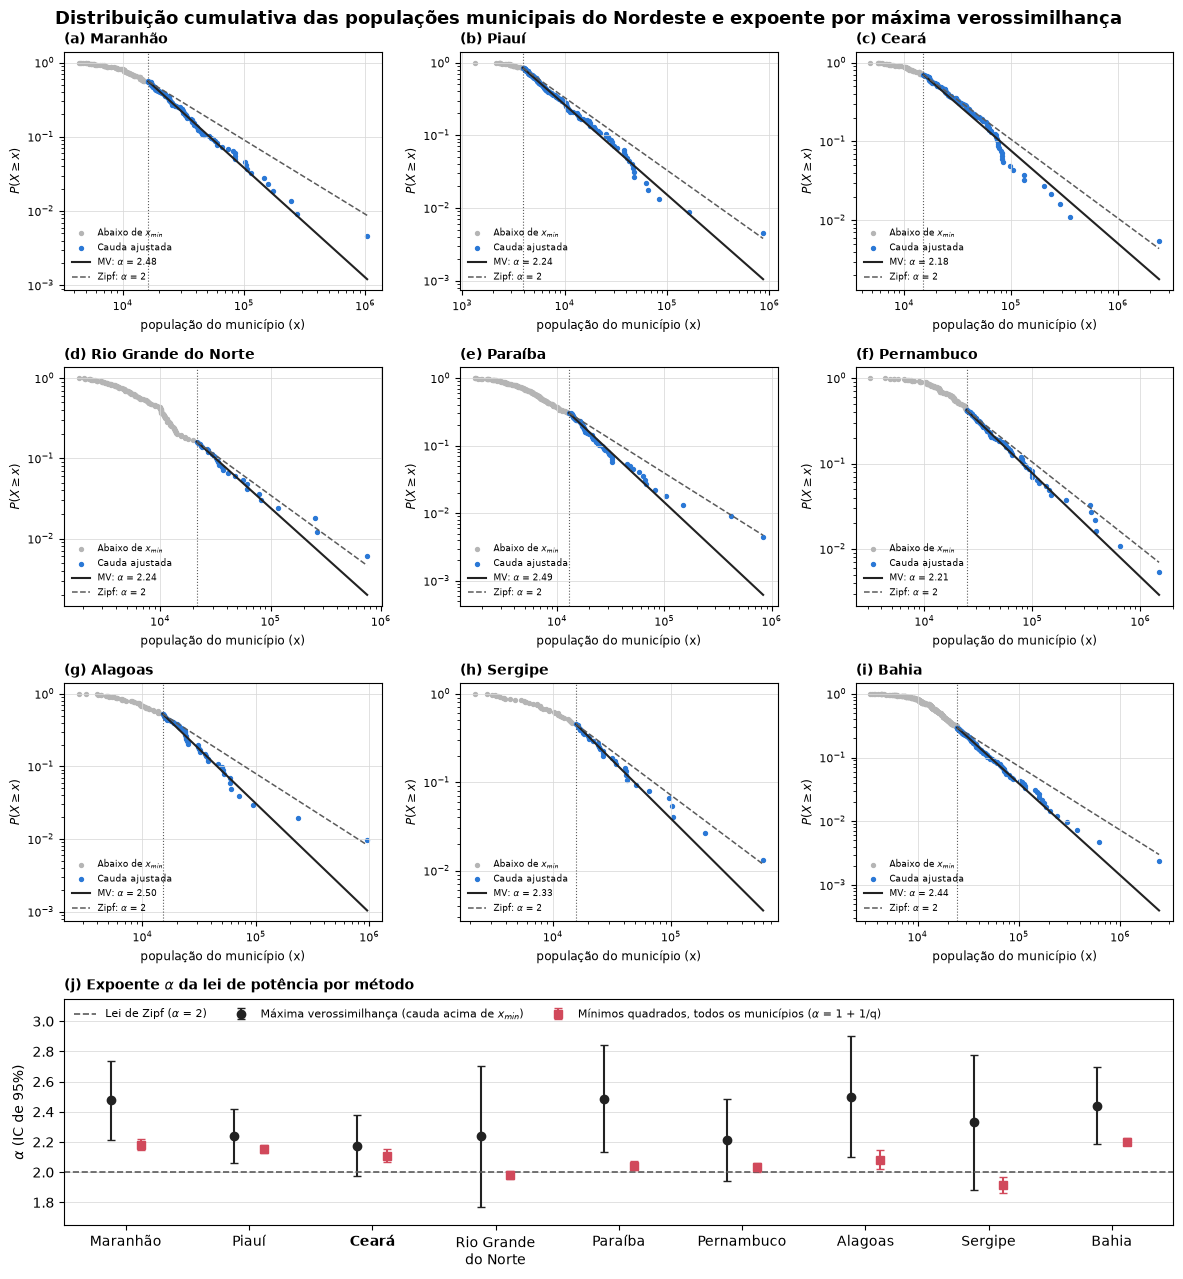

In [17]:
fig = plt.figure(figsize=(12, 13))
grade = fig.add_gridspec(4, 3, height_ratios=[1, 1, 1, 0.95])
paineis = [fig.add_subplot(grade[i, j]) for i in range(3) for j in range(3)]
ax_alfa = fig.add_subplot(grade[3, :])

for ax, sigla, letra in zip(paineis, ESTADOS, 'abcdefghi'):
    tabela, _ = estados[sigla]
    ajuste = ajustes_mv[sigla]
    pop = np.sort(tabela['populacao'].to_numpy())[::-1]
    ccdf = np.arange(1, len(pop) + 1) / len(pop)        # P(X >= x) = posição / n
    na_cauda = pop >= ajuste['x_min']
    ax.scatter(pop[~na_cauda], ccdf[~na_cauda], s=8, color='#B5B5B5', label=r'Abaixo de $x_{min}$')
    ax.scatter(pop[na_cauda], ccdf[na_cauda], s=8, color=COR_CEARA, label='Cauda ajustada')
    # A curva começa em P(X >= x_min) = n_cauda / n e cai com expoente alfa - 1.
    x_linha = np.logspace(np.log10(ajuste['x_min']), np.log10(pop[0]), 100)
    inicio = ajuste['n_cauda'] / len(pop)
    ax.plot(x_linha, inicio * (x_linha / ajuste['x_min']) ** (1 - ajuste['alfa']),
            color='#222222', linewidth=1.5, label=rf"MV: $\alpha$ = {ajuste['alfa']:.2f}")
    ax.plot(x_linha, inicio * (x_linha / ajuste['x_min']) ** (-1), '--', color='#5B5B5B',
            linewidth=1.1, label=r'Zipf: $\alpha$ = 2')
    ax.axvline(ajuste['x_min'], color='#5B5B5B', linewidth=0.8, linestyle=':')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f"({letra}) {ESTADOS[sigla]['nome']}", loc='left', fontweight='bold', fontsize=10)
    ax.set_xlabel('população do município (x)', fontsize=8.5)
    ax.set_ylabel(r'$P(X \geq x)$', fontsize=8.5)
    ax.tick_params(labelsize=8)
    ax.grid(True, color='#D9D9D9', linewidth=0.55)
    ax.legend(frameon=False, fontsize=6.5, loc='lower left')

siglas = list(ESTADOS)
posicoes = np.arange(len(siglas))
tabela_mv = maxima_verossimilhanca.set_index('UF').loc[siglas]
for desloc, coluna, inferior, superior, estilo, cor, rotulo in [
    (-0.12, 'alfa', 'alfa_IC95_inferior', 'alfa_IC95_superior', 'o', '#222222',
     r'Máxima verossimilhança (cauda acima de $x_{min}$)'),
    (0.12, 'alfa_equivalente_mmq', None, None, 's', '#D1495B',
     r'Mínimos quadrados, todos os municípios ($\alpha$ = 1 + 1/q)'),
]:
    valores = tabela_mv[coluna].to_numpy()
    if inferior is None:
        # O IC de q (seção 12) vira IC de alfa pela mesma transformação.
        q_inf = np.array([-resultados_estados[s]['todos']['IC95_superior'] for s in siglas])
        q_sup = np.array([-resultados_estados[s]['todos']['IC95_inferior'] for s in siglas])
        limites_inf, limites_sup = 1 + 1 / q_sup, 1 + 1 / q_inf
    else:
        limites_inf, limites_sup = tabela_mv[inferior].to_numpy(), tabela_mv[superior].to_numpy()
    ax_alfa.errorbar(posicoes + desloc, valores, yerr=[valores - limites_inf, limites_sup - valores],
                     fmt=estilo, color=cor, ecolor=cor, elinewidth=1.5, capsize=3, markersize=6,
                     label=rotulo)
ax_alfa.axhline(2, color='#5B5B5B', linestyle='--', linewidth=1.2, label=r'Lei de Zipf ($\alpha$ = 2)')
ax_alfa.set_xticks(posicoes, [ESTADOS[s]['nome'].replace('Rio Grande do Norte', 'Rio Grande\ndo Norte') for s in siglas])
ax_alfa.get_xticklabels()[siglas.index('CE')].set_fontweight('bold')
ax_alfa.set_xlim(-0.5, len(siglas) - 0.5)
ax_alfa.set_ylim(1.65, 3.15)
ax_alfa.set_ylabel(r'$\alpha$ (IC de 95%)')
ax_alfa.set_title(r'(j) Expoente $\alpha$ da lei de potência por método', loc='left',
                  fontweight='bold', fontsize=10)
ax_alfa.grid(True, axis='y', color='#D9D9D9', linewidth=0.55)
ax_alfa.legend(frameon=False, fontsize=8, loc='upper left', ncols=3)

fig.suptitle('Distribuição cumulativa das populações municipais do Nordeste e expoente por máxima verossimilhança',
             fontsize=13, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT / 'figura_maxima_verossimilhanca.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
maxima_verossimilhanca.to_csv(OUTPUT / 'maxima_verossimilhanca_estados.csv', index=False,
                              encoding='utf-8-sig')
print('Arquivo salvo em:', (OUTPUT / 'maxima_verossimilhanca_estados.csv').resolve())

Arquivo salvo em: /home/davvi/Programing/Unifor/ciencia_cidades/notebook_output/v5/maxima_verossimilhanca_estados.csv


### Valores esperados da estimação por máxima verossimilhança

| Resultado | Maranhão | Piauí | Ceará | Rio Grande do Norte | Paraíba | Pernambuco | Alagoas | Sergipe | Bahia |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| $x_{\min}$ (habitantes) | 16.267 | 3.904 | 15.157 | 21.499 | 12.904 | 24.587 | 15.032 | 15.719 | 24.661 |
| Municípios na cauda | 121 | 189 | 129 | 27 | 68 | 78 | 54 | 34 | 123 |
| $\alpha$ (máxima verossimilhança) | 2,476 ± 0,134 | 2,239 ± 0,090 | 2,176 ± 0,104 | 2,237 ± 0,238 | 2,487 ± 0,180 | 2,213 ± 0,137 | 2,500 ± 0,204 | 2,330 ± 0,228 | 2,441 ± 0,130 |
| $q = 1/(\alpha - 1)$ | 0,677 | 0,807 | 0,850 | 0,808 | 0,672 | 0,824 | 0,667 | 0,752 | 0,694 |
| $p$ do teste $\alpha = 2$ | < 0,001 | 0,008 | 0,089 | 0,319 | 0,007 | 0,120 | 0,014 | 0,148 | < 0,001 |
| $p$ de aderência (bootstrap) | 0,690 | 0,885 | 0,033 | 0,900 | 0,435 | 0,836 | 0,180 | 0,926 | 0,728 |
| $\alpha$ equivalente ao $q$ de mínimos quadrados (todos) | 2,183 | 2,152 | 2,109 | 1,981 | 2,041 | 2,033 | 2,081 | 1,913 | 2,203 |
| População nos 10% maiores municípios | 48,3% | 57,4% | 54,1% | 61,1% | 58,1% | 56,1% | 55,5% | 56,8% | 52,7% |

O $p$ de aderência pode variar um pouco na terceira casa decimal se a semente ou o número de repetições do bootstrap mudar.

## 14. A capital é grande demais ou faltam cidades médias?

As versões anteriores diziam que Fortaleza é "grande demais" porque fica acima da reta da lei ajustada. Esse argumento não é suficiente: numa lei de potência, o maior valor de uma amostra varia muito de uma amostra para outra, e a posição do maior ponto na distribuição cumulativa é sempre $1/n$. Newman (2005, seção III.B) mostra como calcular a distribuição do maior valor. Se os $n$ municípios da cauda seguem a lei ajustada, $P(X \ge x) = (x/x_{\min})^{-(\alpha-1)}$ e

$$P(\text{maior} \ge x) = 1 - \left[1 - (x/x_{\min})^{-(\alpha-1)}\right]^n, \qquad \text{mediana do maior} = x_{\min}\left(1 - 2^{-1/n}\right)^{-1/(\alpha-1)}.$$

Um valor pequeno de $P(\text{maior} \ge \text{observado})$ indicaria que a capital é maior do que a lei permite. Calculamos também duas outras grandezas:

- **Razão entre os dois maiores.** Numa lei de potência, o maior valor, dado o segundo, segue a mesma lei com $x_{\min}$ igual ao segundo. Por isso a razão $R$ entre os dois maiores tem $P(R \ge r) = r^{-(\alpha-1)}$, independentemente de $n$. Esse é um teste direto da primazia medida pela razão 1ª/2ª.
- **Municípios com mais de 100 mil habitantes.** Cada município da cauda passa de 100 mil com probabilidade $(10^5/x_{\min})^{-(\alpha-1)}$, de modo que o número de municípios acima desse limite segue uma distribuição binomial. O $p$ de falta é $P(X \le \text{observados})$ e o $p$ de excesso é $P(X \ge \text{observados})$.

In [19]:
linhas_extremos = []
for sigla, ajuste in ajustes_mv.items():
    tabela, _ = estados[sigla]
    pop = tabela['populacao'].to_numpy()
    n, x_min, expoente = ajuste['n_cauda'], ajuste['x_min'], ajuste['alfa'] - 1
    maior, segundo = pop[0], pop[1]
    razao_obs = maior / segundo
    # Probabilidade de um município da cauda passar de 100 mil (só faz sentido se x_min < 100 mil).
    p_100 = (1e5 / x_min) ** (-expoente) if x_min < 1e5 else np.nan
    observados_100 = int((pop >= 1e5).sum())
    linhas_extremos.append({
        'UF': sigla,
        'maior_municipio': tabela.loc[0, 'municipio'],
        'populacao_maior': int(maior),
        'mediana_esperada_maior': x_min * (1 - 0.5 ** (1 / n)) ** (-1 / expoente),
        'p_maior_maior_ou_igual': 1 - (1 - (maior / x_min) ** (-expoente)) ** n,
        'razao_primeiro_segundo': razao_obs,
        'p_razao_maior_ou_igual': razao_obs ** (-expoente),
        'previstos_100_mil': n * p_100,
        'observados_100_mil': observados_100,
        'observados_sobre_previstos': observados_100 / (n * p_100),
        'p_falta_100_mil': stats.binom.cdf(observados_100, n, p_100),
        'p_excesso_100_mil': stats.binom.sf(observados_100 - 1, n, p_100),
    })

extremos = pd.DataFrame(linhas_extremos)
extremos.to_csv(OUTPUT / 'maior_municipio_e_cidades_medias.csv', index=False, encoding='utf-8-sig')
display(extremos.round(3))

,UF,maior_municipio,populacao_maior,mediana_esperada_maior,p_maior_maior_ou_igual,razao_primeiro_segundo,p_razao_maior_ou_igual,previstos_100_mil,observados_100_mil,observados_sobre_previstos,p_falta_100_mil,p_excesso_100_mil
0,MA,São Luís,1037775,538236.158,0.231,3.800,0.139,8.291,10,1.206,0.793,0.317
1,PI,Teresina,866300,361606.392,0.209,5.342,0.125,3.401,2,0.588,0.337,0.856
2,CE,Fortaleza,2428708,1293585.053,0.281,6.828,0.104,14.030,8,0.570,0.051,0.975
3,RN,Natal,751300,419148.994,0.284,2.840,0.275,4.030,4,0.992,0.623,0.589
4,PB,João Pessoa,833932,282812.289,0.129,1.988,0.360,3.236,4,1.236,0.778,0.407
5,PE,Recife,1488920,1210134.263,0.416,2.312,0.362,14.216,12,0.844,0.316,0.784
6,AL,Maceió,957916,275285.867,0.101,4.082,0.121,3.146,2,0.636,0.384,0.830
7,SE,Aracaju,602757,295546.915,0.234,3.134,0.219,2.901,4,1.379,0.840,0.329
8,BA,Salvador,2417678,898927.110,0.153,3.923,0.140,16.362,18,1.100,0.722,0.370


### Valores esperados da seção 14

| Resultado | Maranhão | Piauí | Ceará | Rio Grande do Norte | Paraíba | Pernambuco | Alagoas | Sergipe | Bahia |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Maior município (habitantes) | 1.037.775 | 866.300 | 2.428.708 | 751.300 | 833.932 | 1.488.920 | 957.916 | 602.757 | 2.417.678 |
| Mediana esperada do maior | 538.236 | 361.606 | 1.293.585 | 419.149 | 282.812 | 1.210.134 | 275.286 | 295.547 | 898.927 |
| $P(\text{maior} \ge \text{observado})$ | 0,231 | 0,209 | 0,281 | 0,284 | 0,129 | 0,416 | 0,101 | 0,234 | 0,153 |
| Razão 1ª/2ª | 3,80 | 5,34 | 6,83 | 2,84 | 1,99 | 2,31 | 4,08 | 3,13 | 3,92 |
| $P(R \ge \text{observada})$ | 0,139 | 0,125 | 0,104 | 0,275 | 0,360 | 0,362 | 0,121 | 0,219 | 0,140 |
| Municípios ≥ 100 mil, previstos / observados | 8,3 / 10 | 3,4 / 2 | 14,0 / 8 | 4,0 / 4 | 3,2 / 4 | 14,2 / 12 | 3,1 / 2 | 2,9 / 4 | 16,4 / 18 |
| Observados / previstos | 1,21 | 0,59 | 0,57 | 0,99 | 1,24 | 0,84 | 0,64 | 1,38 | 1,10 |
| $p$ de falta, $P(X \le \text{obs.})$ | 0,793 | 0,337 | 0,051 | 0,623 | 0,778 | 0,316 | 0,384 | 0,840 | 0,722 |
| $p$ de excesso, $P(X \ge \text{obs.})$ | 0,317 | 0,856 | 0,975 | 0,589 | 0,407 | 0,784 | 0,830 | 0,329 | 0,370 |

Nenhuma capital é anômala pela lei ajustada: $P(\text{maior} \ge \text{observado})$ fica entre 0,10 e 0,42 nos nove estados. O Ceará tem a menor razão entre observados e previstos acima de 100 mil habitantes e o menor $p$ de falta da região (0,051), além do menor $p$ da razão 1ª/2ª (0,104).

## 15. Lei de potência ou log-normal?

A seção 13 mostrou que, no Ceará, a lei de potência é rejeitada pelo teste de aderência. A pergunta seguinte, recomendada por Newman (2005, seção II.B) e por Clauset, Shalizi e Newman (2009, seção 5), é se outra distribuição descreve melhor os dados. A candidata mais comum para cidades é a **log-normal**, que também resulta de crescimento proporcional (Eeckhout, 2004) e, num gráfico log-log, parece uma reta numa faixa larga.

Para comparar as duas na mesma cauda ($x \ge x_{\min}$), ajustamos por máxima verossimilhança uma log-normal truncada em $x_{\min}$, com densidade $f(x) / P(X \ge x_{\min})$, e calculamos a razão de log-verossimilhança

$$\mathcal{R} = \sum_{i=1}^{n} \left[\ln p_{\text{potência}}(x_i) - \ln p_{\text{log-normal}}(x_i)\right].$$

$\mathcal{R} > 0$ favorece a lei de potência e $\mathcal{R} < 0$, a log-normal. Como $\mathcal{R}$ é uma soma de termos aleatórios, seu sinal só é confiável se $|\mathcal{R}|$ for grande em relação ao desvio padrão $\sigma_d$ das diferenças pontuais. O $p$ de Vuong, usado por Clauset, Shalizi e Newman (2009), é $p = \operatorname{erfc}\left(|\mathcal{R}| / \sqrt{2 n \sigma_d^2}\right)$; com $p \ge 0{,}1$, o teste não distingue as duas distribuições.

Há um caso especial. Quando $\mu \to -\infty$ e $\sigma \to \infty$, a cauda da log-normal se aproxima de uma lei de potência, e o ajuste pode "escorregar" para esse limite. Isso acontece quando a cauda não tem curvatura que a log-normal possa aproveitar: os dois modelos ficam iguais, $\mathcal{R} \approx 0$, e o teste não informa nada. Marcamos esses casos como **degenerados**, pelo critério de a mediana da log-normal ajustada, $e^{\mu}$, ficar abaixo de 1 habitante.

Nos estados em que o ajuste não é degenerado, testamos também se a log-normal é plausível, pelo mesmo bootstrap paramétrico da seção 13 (1.000 amostras, $x_{\min}$ fixo e parâmetros reestimados em cada amostra).

In [20]:
def log_densidade_potencia(cauda, x_min, alfa):
    return np.log(alfa - 1) - np.log(x_min) - alfa * np.log(cauda / x_min)

LOG_RAIZ_2PI = 0.5 * np.log(2 * np.pi)

def log_densidade_lognormal(cauda, x_min, mu, sigma):
    """Log da densidade log-normal condicionada a X >= x_min: f(x) / P(X >= x_min)."""
    logs = np.log(cauda)
    z = (logs - mu) / sigma
    log_cauda = special.log_ndtr(-(np.log(x_min) - mu) / sigma)
    return -0.5 * z ** 2 - np.log(sigma) - LOG_RAIZ_2PI - logs - log_cauda

def ajustar_lognormal_truncada(cauda, x_min, inicio=None):
    """Máxima verossimilhança da log-normal truncada em x_min."""
    logs = np.log(cauda)

    def menos_log_verossimilhanca(parametros):
        return -np.sum(log_densidade_lognormal(cauda, x_min, parametros[0], np.exp(parametros[1])))

    # Nos dados, usamos vários pontos de partida, porque a verossimilhança da log-normal
    # truncada é achatada; no bootstrap, basta partir dos parâmetros que geraram a amostra.
    if inicio is None:
        partidas = [(m, np.log(s)) for m in [logs.mean(), logs.mean() - 3, logs.mean() - 8]
                    for s in [logs.std(), 1.5, 3.0]]
    else:
        partidas = [(inicio[0], np.log(inicio[1]))]
    melhor = None
    for partida in partidas:
        with np.errstate(all='ignore'):  # o ajuste pode passar por regiões degeneradas
            res = optimize.minimize(menos_log_verossimilhanca, partida, method='Nelder-Mead',
                                    options={'xatol': 1e-7, 'fatol': 1e-9, 'maxiter': 5000})
        if melhor is None or res.fun < melhor.fun:
            melhor = res
    return melhor.x[0], np.exp(melhor.x[1])

def ks_lognormal(cauda, x_min, mu, sigma):
    x = np.sort(cauda)
    n = len(x)
    # Em escala logarítmica, para não dividir 0 por 0 quando x_min fica muito acima da mediana.
    cdf = 1 - np.exp(special.log_ndtr(-(np.log(x) - mu) / sigma) - special.log_ndtr(-(np.log(x_min) - mu) / sigma))
    return max(np.max(np.arange(1, n + 1) / n - cdf), np.max(cdf - np.arange(n) / n))

def sortear_lognormal_truncada(rng, n, x_min, mu, sigma):
    # Sorteia a probabilidade de cauda entre 0 e P(X >= x_min) e inverte a normal pela cauda superior.
    p_cauda = special.ndtr(-(np.log(x_min) - mu) / sigma)
    return np.exp(mu - sigma * special.ndtri(rng.random(n) * p_cauda))

def p_aderencia_lognormal(cauda, x_min, mu, sigma, repeticoes=1000, semente=42):
    """Bootstrap paramétrico com x_min fixo e parâmetros reestimados em cada amostra."""
    rng = np.random.default_rng(semente)
    D_obs = ks_lognormal(cauda, x_min, mu, sigma)
    maiores_ou_iguais = 0
    for _ in range(repeticoes):
        amostra = sortear_lognormal_truncada(rng, len(cauda), x_min, mu, sigma)
        mu_s, sigma_s = ajustar_lognormal_truncada(amostra, x_min, inicio=(mu, sigma))
        maiores_ou_iguais += ks_lognormal(amostra, x_min, mu_s, sigma_s) >= D_obs
    return D_obs, maiores_ou_iguais / repeticoes

linhas_ln = []
ajustes_ln = {}
for sigla, ajuste in ajustes_mv.items():
    tabela, _ = estados[sigla]
    pop = tabela['populacao'].to_numpy(dtype=float)
    cauda = pop[pop >= ajuste['x_min']]
    mu, sigma = ajustar_lognormal_truncada(cauda, ajuste['x_min'])
    ajustes_ln[sigla] = {'mu': mu, 'sigma': sigma}
    diferencas = (log_densidade_potencia(cauda, ajuste['x_min'], ajuste['alfa'])
                  - log_densidade_lognormal(cauda, ajuste['x_min'], mu, sigma))
    R = diferencas.sum()
    sd = diferencas.std()
    # Mediana abaixo de 1 habitante: o ajuste escorregou para o limite da lei de potência.
    degenerado = mu < 0
    D_ln, p_ln = (np.nan, np.nan) if degenerado else p_aderencia_lognormal(cauda, ajuste['x_min'], mu, sigma)
    linhas_ln.append({
        'UF': sigla,
        'n_cauda': len(cauda),
        'mu_lognormal': mu,
        'sigma_lognormal': sigma,
        'ajuste_degenerado': degenerado,
        'R_potencia_menos_lognormal': R,
        'R_normalizado': R / (np.sqrt(len(cauda)) * sd),
        'p_vuong': math.erfc(abs(R) / np.sqrt(2 * len(cauda) * sd ** 2)),
        'D_KS_lognormal': D_ln,
        'p_aderencia_lognormal': p_ln,
        'p_aderencia_potencia': ajuste['p_aderencia'],
    })

lognormal = pd.DataFrame(linhas_ln)
lognormal.to_csv(OUTPUT / 'potencia_versus_lognormal.csv', index=False, encoding='utf-8-sig')
display(lognormal.round(4))

,UF,n_cauda,mu_lognormal,sigma_lognormal,ajuste_degenerado,R_potencia_menos_lognormal,R_normalizado,p_vuong,D_KS_lognormal,p_aderencia_lognormal,p_aderencia_potencia
0,MA,121,-180704.0139,349.8961,True,0.0000,0.0438,0.9651,NaN,NaN,0.690
1,PI,189,-56.0859,7.2964,True,-0.0131,-0.0801,0.9361,NaN,NaN,0.885
2,CE,129,5.9242,2.1096,False,-0.8941,-0.5479,0.5838,0.0594,0.318,0.033
3,RN,27,-476098.9616,620.3206,True,0.0000,0.0168,0.9866,NaN,NaN,0.900
4,PB,68,-727726.8889,699.5471,True,0.0000,0.0765,0.9390,NaN,NaN,0.435
5,PE,78,-77.9431,8.5974,True,-0.0031,-0.0526,0.9580,NaN,NaN,0.836
6,AL,54,-472918.4140,561.4752,True,0.0000,0.1427,0.8866,NaN,NaN,0.180
7,SE,34,-461720.6375,589.1441,True,0.0000,0.0627,0.9500,NaN,NaN,0.926
8,BA,123,-415171.8049,536.7877,True,0.0000,0.0887,0.9293,NaN,NaN,0.728


In [21]:
# No Ceará, o único estado com ajuste log-normal não degenerado, as conclusões da seção 14
# (falta de cidades médias e tamanho de Fortaleza) mudam se o modelo for a log-normal?
ajuste, ln = ajustes_mv['CE'], ajustes_ln['CE']
n_cauda = ajuste['n_cauda']
sf_ln = lambda x: np.exp(special.log_ndtr(-(np.log(x) - ln['mu']) / ln['sigma'])
                         - special.log_ndtr(-(np.log(ajuste['x_min']) - ln['mu']) / ln['sigma']))
observados_100 = int((estados['CE'][0]['populacao'] >= 1e5).sum())
fortaleza_pop = estados['CE'][0]['populacao'].iloc[0]
p100_pot = (1e5 / ajuste['x_min']) ** (1 - ajuste['alfa'])
p100_ln = sf_ln(1e5)
comparacao_modelos_ce = pd.DataFrame([
    {'modelo': 'lei de potência', 'previstos_100_mil': n_cauda * p100_pot,
     'p_falta_100_mil': stats.binom.cdf(observados_100, n_cauda, p100_pot),
     'p_maior_maior_ou_igual_fortaleza': 1 - (1 - (fortaleza_pop / ajuste['x_min']) ** (1 - ajuste['alfa'])) ** n_cauda},
    {'modelo': 'log-normal truncada', 'previstos_100_mil': n_cauda * p100_ln,
     'p_falta_100_mil': stats.binom.cdf(observados_100, n_cauda, p100_ln),
     'p_maior_maior_ou_igual_fortaleza': 1 - (1 - sf_ln(fortaleza_pop)) ** n_cauda},
])
print('Municípios observados acima de 100 mil:', observados_100)
comparacao_modelos_ce.to_csv(OUTPUT / 'ceara_potencia_versus_lognormal_extremos.csv', index=False, encoding='utf-8-sig')
display(comparacao_modelos_ce.round(4))

Municípios observados acima de 100 mil: 8


,modelo,previstos_100_mil,p_falta_100_mil,p_maior_maior_ou_igual_fortaleza
0,lei de potência,14.0298,0.0513,0.2811
1,log-normal truncada,13.1268,0.0825,0.0502


### Valores esperados da seção 15

| UF | Municípios na cauda | $\mu$ | $\sigma$ | Ajuste degenerado | $\mathcal{R}$ | $p$ de Vuong | $p$ de aderência da log-normal | $p$ de aderência da lei de potência |
|---|---:|---:|---:|---|---:|---:|---:|---:|
| MA | 121 | — | — | sim | 0,00 | 0,965 | — | 0,690 |
| PI | 189 | — | — | sim | -0,01 | 0,936 | — | 0,885 |
| CE | 129 | 5,92 | 2,11 | não | -0,89 | 0,584 | 0,318 | 0,033 |
| RN | 27 | — | — | sim | 0,00 | 0,987 | — | 0,900 |
| PB | 68 | — | — | sim | 0,00 | 0,939 | — | 0,435 |
| PE | 78 | — | — | sim | -0,00 | 0,958 | — | 0,836 |
| AL | 54 | — | — | sim | 0,00 | 0,887 | — | 0,180 |
| SE | 34 | — | — | sim | 0,00 | 0,950 | — | 0,926 |
| BA | 123 | — | — | sim | 0,00 | 0,929 | — | 0,728 |

| Modelo (Ceará) | Municípios ≥ 100 mil previstos (observados: 8) | $p$ de falta | $P(\text{maior} \ge \text{Fortaleza})$ |
|---|---:|---:|---:|
| lei de potência | 14,0 | 0,051 | 0,281 |
| log-normal truncada | 13,1 | 0,083 | 0,050 |

Nos oito estados com ajuste degenerado, a log-normal converge para a própria lei de potência ($\mathcal{R} \approx 0$), e o teste não acrescenta informação. No Ceará, a log-normal tem ajuste próprio e é plausível, mas a razão de verossimilhança não a distingue da lei de potência. A falta de cidades médias aparece nos dois modelos; já a conclusão sobre Fortaleza depende do modelo: pela lei de potência a capital é compatível ($P$ = 0,28), pela log-normal fica no limite ($P$ = 0,05).

## 16. Figura do artigo v5

O artigo de 3 páginas tem uma única figura. Em (a), a distribuição cumulativa do Ceará com as três distribuições ajustadas à cauda: a lei de potência de máxima verossimilhança, a Lei de Zipf ($\alpha = 2$) e a log-normal truncada; a faixa sombreada marca os municípios entre 100 mil e 400 mil habitantes. Em (b), o expoente $\alpha$ de cada estado do Nordeste pelos dois métodos, com o Ceará em destaque.

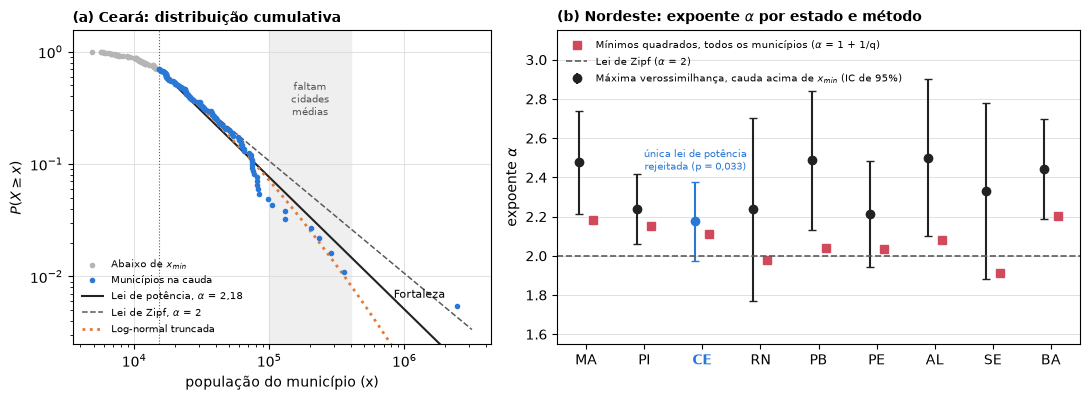

In [22]:
fig, (ax_cdf, ax_alfa) = plt.subplots(1, 2, figsize=(11, 4.1), gridspec_kw={'width_ratios': [1, 1.25]})

tabela, _ = estados['CE']
ajuste, ln = ajustes_mv['CE'], ajustes_ln['CE']
pop = tabela['populacao'].to_numpy(dtype=float)
ccdf = np.arange(1, len(pop) + 1) / len(pop)
na_cauda = pop >= ajuste['x_min']
inicio = ajuste['n_cauda'] / len(pop)
x_linha = np.logspace(np.log10(ajuste['x_min']), np.log10(pop[0] * 1.3), 200)
ax_cdf.axvspan(1e5, 4e5, color='#EFEFEF', zorder=0)
ax_cdf.text(2e5, 0.55, 'faltam\ncidades\nmédias', ha='center', va='top', fontsize=7.5, color='#555555')
ax_cdf.scatter(pop[~na_cauda], ccdf[~na_cauda], s=9, color='#B5B5B5', label=r'Abaixo de $x_{min}$', zorder=2)
ax_cdf.scatter(pop[na_cauda], ccdf[na_cauda], s=9, color=COR_CEARA, label='Municípios na cauda', zorder=3)
ax_cdf.plot(x_linha, inicio * (x_linha / ajuste['x_min']) ** (1 - ajuste['alfa']), color='#222222',
            linewidth=1.5, label=rf"Lei de potência, $\alpha$ = {ajuste['alfa']:.2f}".replace('.', ','))
ax_cdf.plot(x_linha, inicio * (x_linha / ajuste['x_min']) ** (-1), '--', color='#5B5B5B', linewidth=1.1,
            label=r'Lei de Zipf, $\alpha$ = 2')
sf_ln = np.exp(special.log_ndtr(-(np.log(x_linha) - ln['mu']) / ln['sigma'])
               - special.log_ndtr(-(np.log(ajuste['x_min']) - ln['mu']) / ln['sigma']))
ax_cdf.plot(x_linha, inicio * sf_ln, ':', color='#E07B39', linewidth=2, label='Log-normal truncada')
ax_cdf.annotate('Fortaleza', (pop[0], ccdf[0]), xytext=(-8, 6), textcoords='offset points', ha='right', fontsize=8)
ax_cdf.axvline(ajuste['x_min'], color='#5B5B5B', linewidth=0.8, linestyle=':')
ax_cdf.set_xscale('log')
ax_cdf.set_yscale('log')
ax_cdf.set_ylim(bottom=2.5e-3)
ax_cdf.set_xlabel('população do município (x)')
ax_cdf.set_ylabel(r'$P(X \geq x)$')
ax_cdf.set_title('(a) Ceará: distribuição cumulativa', loc='left', fontweight='bold', fontsize=10)
ax_cdf.grid(True, color='#D9D9D9', linewidth=0.55)
ax_cdf.legend(frameon=False, fontsize=7.5, loc='lower left')

siglas = list(ESTADOS)
posicoes = np.arange(len(siglas))
tabela_mv = maxima_verossimilhanca.set_index('UF').loc[siglas]
cores = [COR_CEARA if s == 'CE' else '#222222' for s in siglas]
for pos, s, cor in zip(posicoes, siglas, cores):
    linha = tabela_mv.loc[s]
    ax_alfa.errorbar(pos - 0.12, linha['alfa'],
                     yerr=[[linha['alfa'] - linha['alfa_IC95_inferior']], [linha['alfa_IC95_superior'] - linha['alfa']]],
                     fmt='o', color=cor, ecolor=cor, elinewidth=1.5, capsize=3, markersize=6)
ax_alfa.plot(posicoes + 0.12, tabela_mv['alfa_equivalente_mmq'], 's', color='#D1495B', markersize=5.5)
ax_alfa.errorbar([], [], yerr=[], fmt='o', color='#222222', capsize=3,
                 label=r'Máxima verossimilhança, cauda acima de $x_{min}$ (IC de 95%)')
ax_alfa.plot([], [], 's', color='#D1495B', label=r'Mínimos quadrados, todos os municípios ($\alpha$ = 1 + 1/q)')
ax_alfa.axhline(2, color='#5B5B5B', linestyle='--', linewidth=1.2, label=r'Lei de Zipf ($\alpha$ = 2)')
p_ce = tabela_mv.loc['CE', 'p_aderencia']
ax_alfa.annotate(f'única lei de potência\nrejeitada (p = {p_ce:.3f})'.replace('.', ','),
                 (siglas.index('CE') - 0.12, tabela_mv.loc['CE', 'alfa_IC95_superior']), xytext=(0, 6),
                 textcoords='offset points', ha='center', va='bottom', fontsize=7.5, color=COR_CEARA)
ax_alfa.set_xticks(posicoes, siglas)
ax_alfa.get_xticklabels()[siglas.index('CE')].set_fontweight('bold')
ax_alfa.get_xticklabels()[siglas.index('CE')].set_color(COR_CEARA)
ax_alfa.set_xlim(-0.5, len(siglas) - 0.5)
ax_alfa.set_ylim(1.55, 3.15)
ax_alfa.set_ylabel(r'expoente $\alpha$')
ax_alfa.set_title(r'(b) Nordeste: expoente $\alpha$ por estado e método', loc='left', fontweight='bold', fontsize=10)
ax_alfa.grid(True, axis='y', color='#D9D9D9', linewidth=0.55)
ax_alfa.legend(frameon=False, fontsize=7.5, loc='upper left')

fig.tight_layout()
fig.savefig(OUTPUT / 'figura_artigo_v5.png', dpi=300, bbox_inches='tight')
plt.show()